In [268]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

### Loading Data Set and viewing it

In [269]:
df=pd.read_csv('bank.csv', sep=';')
df.head(5)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [270]:
df['month'].unique()

array(['may', 'jun', 'jul', 'aug', 'oct', 'nov', 'dec', 'jan', 'feb',
       'mar', 'apr', 'sep'], dtype=object)

In [271]:
df['job'].unique()

array(['management', 'technician', 'entrepreneur', 'blue-collar',
       'unknown', 'retired', 'admin.', 'services', 'self-employed',
       'unemployed', 'housemaid', 'student'], dtype=object)

In [272]:
df.tail(5)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


In [273]:
df.shape[0]

45211

#### * No of rowns present in the dataset is : 45211 (before removal of outlier)

In [274]:
int(df['balance'].mean())

1362

In [275]:
int(df['duration'].mean())

258

#### <li>Checking Nan Values
#### <li>Checking for duplicates

In [276]:
df.isna().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

#####  <li>the data set is having 0 isna values so there is no need of filling the dataset 

In [277]:
df.duplicated().sum()

np.int64(0)

##### <li> its saying 0 duplicates 

### Now checking mean , median and mode along with some other statistical terms needed

In [278]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


##### <li> it expressed all the required statistical and mathamitical value needed for all the numerical calumns available in the dataset

##### * barchart representation of max value of age ,the max value balance and max value of  removel of outlier for the purpose of checking of max value difference in the pdays

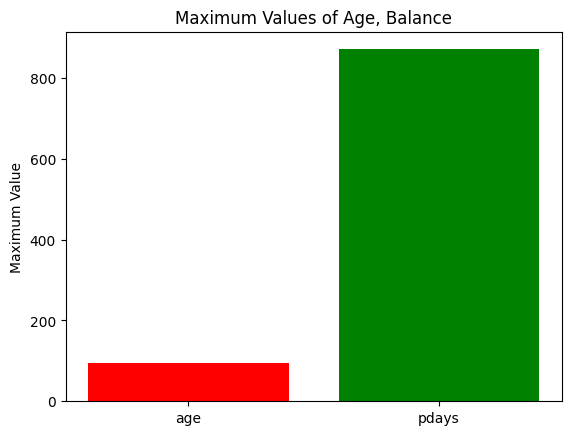

In [297]:
max_age=df['age'].max()
max_pdays=df['pdays'].max()

plt.bar(['age','pdays'],[max_age,max_pdays],color=['red','green'])
plt.ylabel('Maximum Value')
plt.title('Maximum Values of Age, Balance')
plt.show()

In [280]:
df.head(5)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


##### * pie chart of no of customers having house in terms of yes or no before removing the outliers

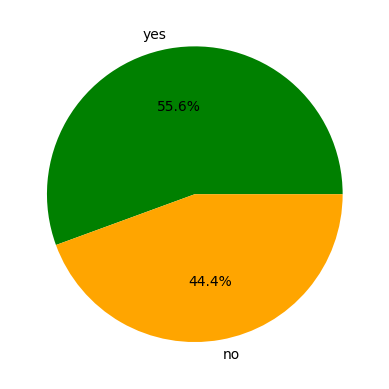

In [281]:
p = df["housing"]
counts = p.value_counts()

plt.pie(
    counts,
    labels=counts.index,
    colors=["green","Orange"],
    autopct="%1.1f%%"
)
plt.show()

## Now the process Removing the outliers

### checking for outliers in the Age 
#### * because that i want to find the number of customers on the basis of age group

#### * Outlier removal process

Text(0.5, 0, 'Marks')

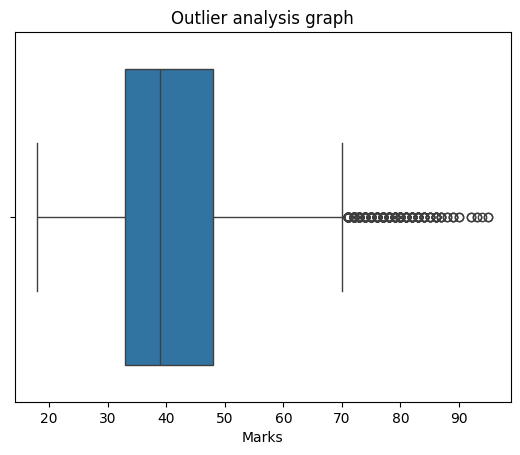

In [282]:
age=df['age']
plt.Figure(figsize=(10,10))
sns.boxplot(x=age)
plt.title("Outlier analysis graph")
plt.xlabel("Marks")

##### * graph before removal of outlier

for the process of removing the outlier we use to use the below steps

1. finding the q1 , q2 and q3
    q1=25%
    q2=50%
    q3=75%
    
2. the dataset outside this q1 and q3 use to be considered as the outlier in graph the data present inside the box is a actual group that comes between q1 and q3

3. now we will find q1 , q2 , q3 percentile

4. then we will apply the iqr formula
         formula : iqr=q3-q1

5. in final we will plot the dataset in between the q1 and q3 using lower limit and upper limit formula
         formula : lower limit = q1-1.5*iqr
                   upper limit = q3+1.5*iqr

7. in final we will check the 


structure it well for markdown

In [283]:
age.describe()

count    45211.000000
mean        40.936210
std         10.618762
min         18.000000
25%         33.000000
50%         39.000000
75%         48.000000
max         95.000000
Name: age, dtype: float64

In [284]:
q1=df['age'].quantile(0.25)
q3=df['age'].quantile(0.75)
iqr=q3-q1
lower_limit=q1-1.5*iqr
upper_limit=q3+1.5*iqr
final_df=final_df = df[df["age"].between(lower_limit, upper_limit)]

In [285]:
final_df.shape[0]

44724

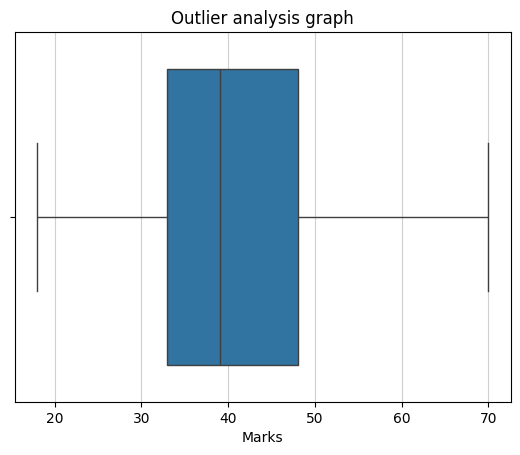

In [286]:
plt.Figure(figsize=(10,10))
sns.boxplot(x=final_df['age'])
plt.title("Outlier analysis graph")
plt.xlabel("Marks")
plt.grid(axis="x", alpha=0.6)

#### * Graph After Removal Of the outlier

### Feature Selection

##### * Matrix Corellation

#### * Here we are checking the relationship between the corresponding and target variable using which we will get the proper corresesponding and taget features(columns)

##### 1. formula that we are using over here is 

            correlation=(cov(x,y))/sqrt((std(x))*(std(y)))

####  2. here we use to see the threshhold of -1 to +1 in which we use to consider the std threshhold of 0.7 to 1.0 this is considered as strongest corellation

In [292]:
cor=final_df.corr(numeric_only=True).abs()
cor

,age,balance,day,duration,campaign,pdays,previous
age,1.000000,0.086714,0.007038,0.016227,0.012869,0.032578,0.009489
balance,0.086714,1.000000,0.005294,0.019215,0.013328,0.000453,0.013611
day,0.007038,0.005294,1.000000,0.029863,0.163304,0.094075,0.052174
duration,0.016227,0.019215,0.029863,1.000000,0.084458,0.002952,0.000584
campaign,0.012869,0.013328,0.163304,0.084458,1.000000,0.088486,0.032455
pdays,0.032578,0.000453,0.094075,0.002952,0.088486,1.000000,0.454488
previous,0.009489,0.013611,0.052174,0.000584,0.032455,0.454488,1.000000


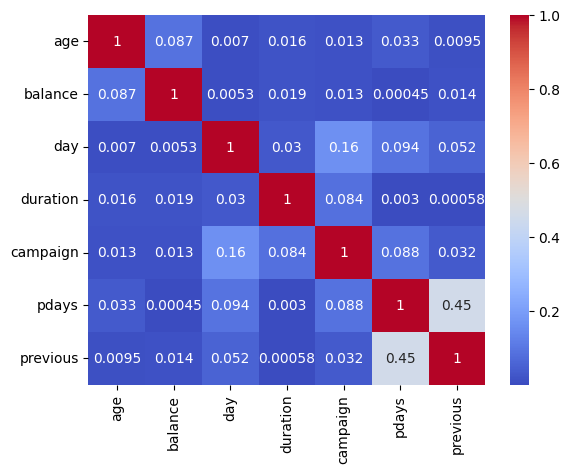

In [295]:
plt.Figure(figsize=(10,10))
sns.heatmap(cor, annot=True, cmap="coolwarm")
plt.show()

##### * After reviewing the graph we can see there is no connectivity thats getting establishing between any of the columns hence we are not moving further